# 04 · Periodos de retorno de M≥6 y M≥7

> **Advertencia:** esto estima una frecuencia media de largo plazo. **No predice** cuándo ni dónde será el próximo sismo fuerte.

Los sismos se desagrupan (Gardner-Knopoff) para cumplir el supuesto de Poisson; la línea base es contar y dividir por los años.

In [1]:
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display

from sismos import config, analisis, graficos
from sismos import gutenberg_richter as gr

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
ecuador = pd.read_parquet(config.CATALOGO_ECUADOR)
mundo = pd.read_parquet(config.CATALOGO_CINTURON)
historico = pd.read_parquet(config.CATALOGO_HISTORICO)
resultados = json.loads(config.RESULTADOS.read_text(encoding="utf-8"))
print(f"Ecuador: {len(ecuador):,} sismos · mundo M≥5: {len(mundo):,} · histórico M≥6: {len(historico):,}")

Ecuador: 3,214 sismos · mundo M≥5: 87,784 · histórico M≥6: 139


In [2]:
r = resultados['retorno']
print('Mc =', r['mc'], '· años =', r['anios'], '· sismos principales =', r['eventos_principales'], '· % quitados como réplicas/premonitores =', r['pct_eliminados_desagrupar'])

Mc = 5.6 · años = 56 · sismos principales = 1658 · % quitados como réplicas/premonitores = 48.4


In [3]:
tabla = pd.read_csv(config.REPORTES / 'periodos_retorno.csv')
tabla.round(3)

,modelo,magnitud,periodo_retorno_anios,periodo_ic95_bajo,periodo_ic95_alto,prob_anual,prob_50_anios
0,GR desagrupado (principal),6.0,0.913,0.753,1.162,0.666,1.000
1,GR desagrupado (principal),7.0,4.988,3.296,8.488,0.182,1.000
2,GR con réplicas,6.0,0.683,0.571,0.839,0.769,1.000
3,GR con réplicas,7.0,4.803,3.272,7.976,0.188,1.000
4,GR solo superficiales <70 km,6.0,1.648,1.252,2.244,0.455,1.000
5,GR solo superficiales <70 km,7.0,10.393,5.975,21.943,0.092,0.992
6,Conteo 1970–2025 (línea base),6.0,1.018,0.782,1.352,0.625,1.000
7,Conteo 1970–2025 (línea base),7.0,3.500,2.155,6.123,0.249,1.000
8,Conteo 1900–2025 (línea base),7.0,5.040,3.414,7.788,0.180,1.000


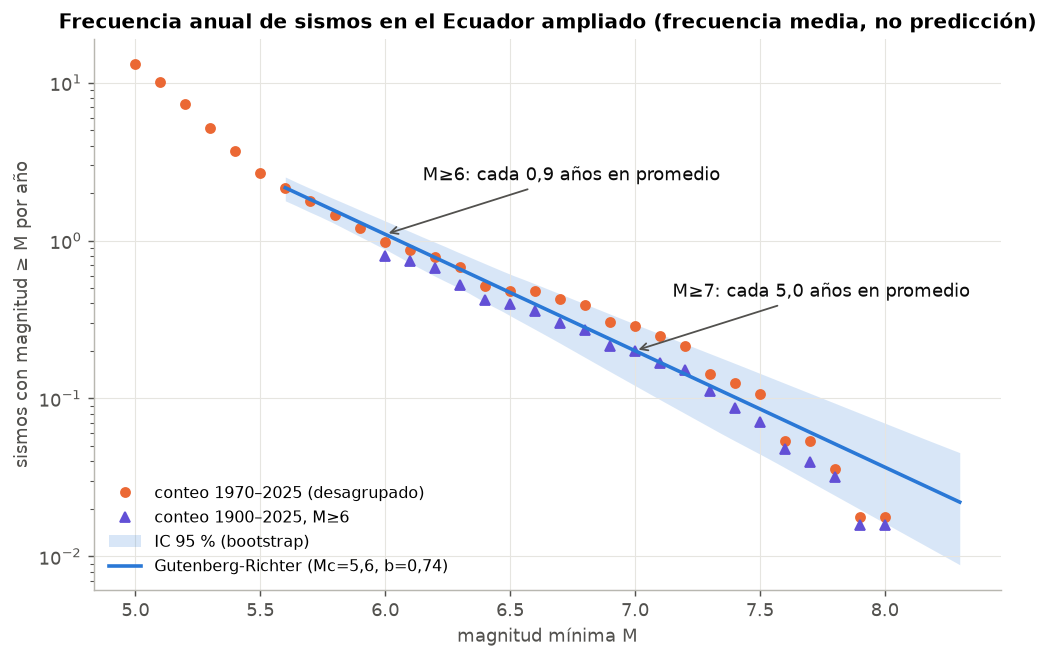

In [4]:
display(Image(config.FIGURAS / '11_periodos_de_retorno.png'))

Con el Mc de máxima curvatura (5,0) la recta es más empinada y el periodo de retorno de M≥7 sale varias veces más largo que lo observado:

In [5]:
rm = resultados['retorno_con_mc_maxc']
pd.DataFrame(rm['gr_desagrupado'])[['magnitud', 'periodo_retorno_anios', 'periodo_ic95', 'prob_anual']]

,magnitud,periodo_retorno_anios,periodo_ic95,prob_anual
0,6.0,1.087,"[0.8806218871141498, 1.3893729662739047]",0.601
1,7.0,15.469,"[10.245254355651268, 24.899569403756384]",0.063


Sismos M≥7 desde 1900 (catálogo histórico desagrupado):

In [6]:
pd.DataFrame(r['historico_m7'])

,tiempo,mw,profundidad_km,lugar
0,1901-01-07 00:29:00+00:00,7.2,NaN,Near the coast of Ecuador
1,1906-01-31 15:36:10+00:00,8.8,20.0,1906 Ecuador-Colombia Earthquake
2,1906-09-28 15:24:36.940000+00:00,7.4,100.0,"16 km W of Barranca, Peru"
3,1928-05-14 22:14:48.040000+00:00,7.3,10.0,"23 km N of Bellavista, Peru"
4,1942-05-14 02:13:27.010000+00:00,7.8,20.0,"12 km SE of Pedernales, Ecuador"
5,1953-12-12 17:31:29.840000+00:00,7.3,25.0,"14 km NNE of Zorritos, Peru"
6,1956-01-16 23:37:45.120000+00:00,7.0,20.0,"7 km NNE of Tosagua, Ecuador"
7,1958-01-19 14:07:28.470000+00:00,7.6,27.5,near the coast of Ecuador
8,1967-02-09 15:24:46.750000+00:00,7.0,35.0,"41 km SE of Baraya, Colombia"
9,1970-12-10 04:34:40.150000+00:00,7.2,19.2,"9 km ENE of Papayal, Peru"
